In [1]:
import numpy as np
import matplotlib.pyplot as  plt
import pandas as pd
import os
import scipy

### Signalness Computation
The IceCube signalness is computed with:
$$
Signalness(E, \delta) = \frac{N_{signal}(E, \delta)}{N_{signal}(E, \delta) + N_{background}(E, \delta)}
$$
Its uses a powrlaw astrophysical neutrino spectrum of  $E^{-2.19}$. In practice, this is actually colmputed with:

$$
Signalness(E, \delta) = \frac{N_{signal}(E>E_{\mu,recon},\delta)}{N_{signal}(E>E_{\mu,recon},\delta)+N_{background}(E>E_{\mu,recon},\delta)}
$$


[IceCat-1](https://arxiv.org/abs/2304.01174) is public on [dataverse](https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/SCRUCD&version=4.0).


In [28]:
icecat1_path = '/Users/cristozilleruelo/Desktop/DESY/Thesis/IceCat-1/'
alerts_path = os.path.join(icecat1_path,  'IceCube_Gold_Bronze_Tracks.csv')
eff_areas_path = os.path.join(icecat1_path, 'eff_area', 'Effa_ehegold.txt')#'Effa_all_streams_gold_bronze.txt')
with open(alerts_path, 'r') as file:
    ic_alerts = pd.read_csv(file)

#get effective areas:
with open(eff_areas_path,  'r') as file:
    eff_areas = pd.read_table(file)
    

In [29]:
ic_alerts[['DEC', 'DEC_ERR_MINUS', 'DEC_ERR_PLUS', 'ENERGY', 'SIGNAL', 'FAR']]

,DEC,DEC_ERR_MINUS,DEC_ERR_PLUS,ENERGY,SIGNAL,FAR
0,-1.94,1.12,0.97,187.0,0.508,1.30
1,35.64,1.05,1.30,294.0,0.750,0.25
2,5.38,0.90,0.79,109.0,0.257,4.34
3,40.67,0.44,0.44,72.0,0.778,0.11
4,6.99,0.83,0.98,160.0,0.396,1.92
...,...,...,...,...,...,...
343,12.33,1.76,1.30,145.0,0.394,1.68
344,7.63,0.68,0.60,113.0,0.294,3.38
345,31.83,1.77,2.08,168.0,0.544,0.88
346,25.04,0.99,1.15,442.0,0.842,0.45


In [31]:
fig = plt.figure(figsize=(8,5))
print(eff_areas.keys())
for key in eff_areas.keys()[1:]:
    plt.plot(eff_areas['#E '], eff_areas[key], label=fr'$\delta=[{key}]\degree$')
    
plt.xscale('log')
plt.yscale('log')
plt.xlim(1e4, 1e9)
plt.ylim(1e-2, 1e4)
plt.xlabel(r'$E_\nu[GeV]$',  fontsize=16)
plt.ylabel(r'$A^{eff}\;[m^2]$',  fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.title('Effective Area', fontsize=16)
plt.show()

Index(['100.0 ', ' 0.0 ', ' 0.0 .1', ' 0.0 .2', ' 0.0 .3', ' 0.0'], dtype='object')


KeyError: '#E '

<Figure size 800x500 with 0 Axes>

In [5]:
def effective_area(E_nu, dec):
    if -90 <= dec <= -30:
        area_values = eff_areas[' -90- -30 '].values
    elif  -30 <= dec <= -5:
        area_values = eff_areas[' -30- -5 '].values
    elif -5 <= dec <= 0:
        area_values = eff_areas[' -5-0 '].values
    elif 0 <= dec <= 30:
        area_values = eff_areas[' 0-30 '].values
    elif 30 <= dec <= 90:
        area_values = eff_areas[' 30-90 '].values

    f = scipy.interpolate.interp1d(eff_areas["#E "].values, area_values)

    try:
        A_eff = f(E_nu) * 1e4#in cm^2
    except ValueError:
        #interpolation out of range:
        A_eff = 0
    return   A_eff

In [6]:
E_nu = 100 *  10**3  #GeV
A_eff = effective_area(E_nu, 25)
print('For E_nu = ', E_nu, ' GeV and dec = ',  25,  ' deg, the effective area is: ',  A_eff, ' m^2')

For E_nu =  100000  GeV and dec =  25  deg, the effective area is:  164200.38686002148  m^2


### Astrophysical Flux
In IceCat-1,  they use a power law distribution taken from [Haack & Wiebusch 2017](https://pos.sissa.it/301/1005) of:
$$
\frac{d\phi_{\nu+\bar \nu}}{dE} = 1.01\pm^{0.26}_{0.23} \Big(\frac{E}{100\,\text{TeV}}\Big)^{-2.19\pm0.1}\cdot 10^{-18}\;[\text{GeV}^{-1}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]
$$

In [7]:
def d_N_astro_dE(E_nu, norm=1.01, gamma=2.19):
    '''
    E_nu: float or array, in  GeV
    '''
    return norm * (E_nu * 1e-3  / 100) ** (-1 *gamma) * 1e-18

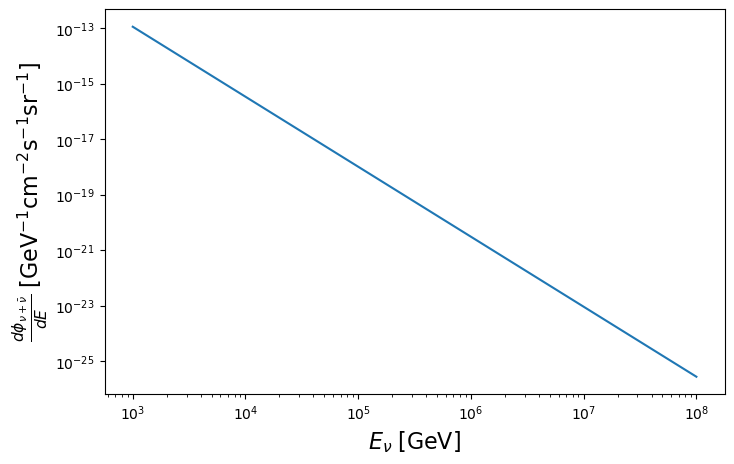

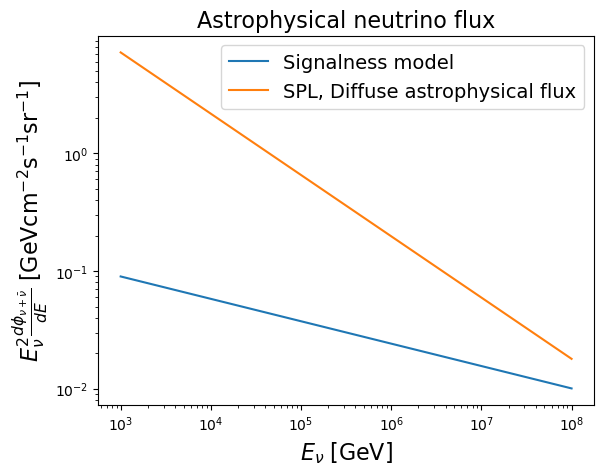

In [8]:
fig = plt.figure(figsize=(8,5))
E_range = np.logspace(3, 8, 1000)
plt.plot(E_range, d_N_astro_dE(E_range, gamma=2.52))
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}^{-1}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.show()

plt.plot(E_range, d_N_astro_dE(E_range * 1e-3) * E_range ** 2, label='Signalness model')
plt.plot(E_range, d_N_astro_dE(E_range * 1e-3, gamma=2.52, norm=1.80) * E_range ** 2, label='SPL, Diffuse astrophysical flux')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Astrophysical neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.show()

### Backrgound model

We have the [nuflux](https://docs.icecube.aq/nuflux/main/overview.html) background model, which can compute the atmospheric bakcground from a spexcific population. 

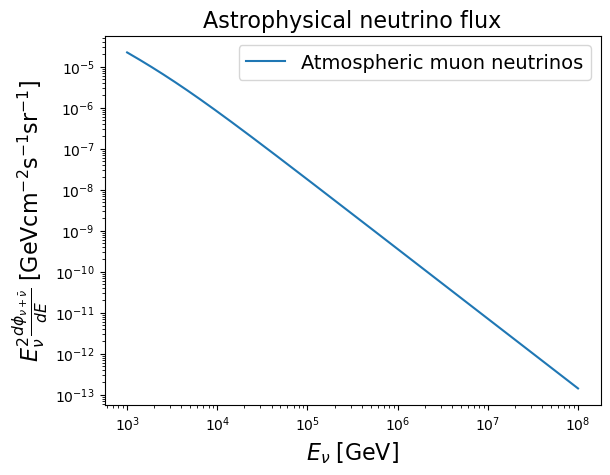

In [9]:
import nuflux
flux = nuflux.makeFlux('honda2006')#('CORSIKA_GaisserH3a_average')
nu_type=nuflux.NuMu
nu_energy=1e3 # in GeV
nu_cos_zenith = 0.5
flux.getFlux(nu_type, nu_energy, nu_cos_zenith)

plt.plot(E_range, flux.getFlux(nu_type, E_range, nu_cos_zenith) * E_range **  2, label='Atmospheric muon neutrinos')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Astrophysical neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.show()

In [10]:
# help(nuflux)

### Signalness Computation
First lets get the overview of both populations:


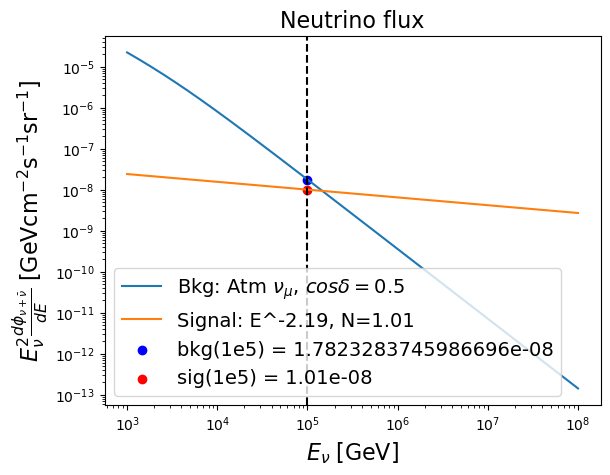

dNs / (dNs +  dNbkg) (1e5 GeV) =  0.361705309872505


In [11]:
E_range = np.logspace(3, 8, 1000)
plt.plot(E_range, flux.getFlux(nu_type, E_range, 0.5) * E_range **  2, label=r'Bkg: Atm $\nu_\mu$, $cos\delta=0.5$')
plt.plot(E_range, d_N_astro_dE(E_range) * E_range ** 2, label='Signal: E^-2.19, N=1.01')
plt.axvline(1e5, c='black', linestyle='dashed')
plt.scatter(1e5, flux.getFlux(nu_type, 1e5, 0.5) * 1e5 **  2, label=f'bkg(1e5) = {flux.getFlux(nu_type, 1e5, 0.5) * 1e5 **  2}', c='blue')
plt.scatter(1e5, d_N_astro_dE(1e5) * 1e5 **  2, label=f'sig(1e5) = {d_N_astro_dE(1e5) * 1e5 **  2}', c='red')
# plt.plot(E_range, d_N_astro_dE(E_range * 1e-3, gamma=2.52, norm=1.80) * E_range ** 2, label='Signal: SPL Diffuse')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.show()



print('dNs / (dNs +  dNbkg) (1e5 GeV) = ', d_N_astro_dE(1e5) / (d_N_astro_dE(1e5) + flux.getFlux(nu_type, 1e5, 0.5)))

We need to compute the integral:
$$
N(E>E_\nu,\delta) = \int_{E_\nu}^\infty \frac{d\phi_{\nu+\bar \nu}}{dE}dE \cdot A_{Eff}(E_\nu, \delta)
$$
To recover the standard signalness $\frac{N_S}{N_B+N_S}$, and compare it to the ratio:

$$
\frac{\frac{dN_S}{dE}}{\frac{dN_B}{dE}+\frac{dN_S}{dE}}
$$
To see how different the signalness aproximation is. For computation purposes, we can approximate the integral upper limit to $E_{max}=10^8$ due to the flux's steep decline.

In [12]:
def signalness_int(E_nu, dec, E_max=1e9, debug=False):
    '''
    Computes  the signalness integrating both  powerlaws to infity: N(E>E_nu) -> s = N_s  / N_s + N_b
    E_nu: float, in GeV
    '''
    # int_range, step = np.linspace(E_nu, E_max, 10000, retstep=True)
    int_range = np.logspace(np.log10(E_nu), np.log10(E_max), 1000)
    # step = int_range[1:] - int_range[:-1] 
    
    A_eff = np.array([effective_area(E, dec)  for E in int_range])
    y_s = d_N_astro_dE(int_range) * A_eff 
    
    N_s = scipy.integrate.trapezoid(y_s, int_range) 

    nu_cos_zenith = np.cos(np.deg2rad(dec))
    y_b = flux.getFlux(nu_type, int_range, nu_cos_zenith) * A_eff
    N_b = scipy.integrate.trapezoid(y_b, int_range)  


    if debug:
        print('\nItegration values')
        print("E_nu: ", E_nu, ' GeV')
        print('dec: ', dec, ' deg')
        print('integration range: [', min(int_range), ', ', max(int_range), ']')
        print("A_eff range: [", min(A_eff), ', ', max(A_eff), '] cm^2')
        print('N_s: ', N_s)
        print('N_b: ', N_b, '\n')

    return N_s / (N_s + N_b)

def signalness_diff(E_nu, dec, E_max=1e9, debug=False):
    '''
    Computes the signalness by directly evaluating the differential fluxes in the ratio:
    s = dN_s/dE / (dN_s/dE + dN_b/dE)

    E_nu: float, in GeV
    '''

    dN_s = d_N_astro_dE(E_nu)
    nu_cos_zenith = np.cos(np.deg2rad(dec))
    dN_b = flux.getFlux(nu_type, E_nu, nu_cos_zenith)

    if debug:
        print('\nDifferential values')
        print("E_nu: ", E_nu, ' GeV')
        print('dec: ', dec, ' deg')
        print('dN_s: ', dN_s)
        print('dN_b: ', dN_b, '\n')

    return dN_s / (dN_s + dN_b)

    
##TO DO: add area in CM, multiply by energis
    

In [13]:
E_max = 1e9
E_range = np.logspace(3, 8, 100) #in GeV
int_signalness  = []
dif_signalness = []
dec = 45 #deg
for E_test in E_range:
    #First we compute the integral version
    int_signalness.append(signalness_int(E_test, dec))

    #then the  diferential evaluation
    dif_signalness.append(signalness_diff(E_test, dec))
    

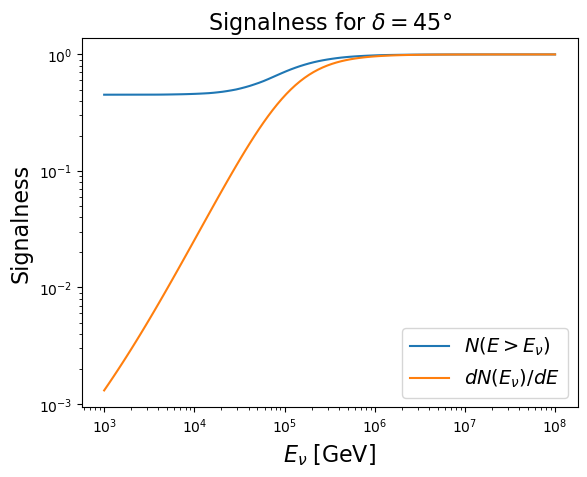

In [14]:
plt.plot(E_range, int_signalness, label=r'$N(E>E_\nu)$')
plt.plot(E_range, dif_signalness, label=r'$dN(E_\nu)/dE$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel('Signalness', fontsize=16)
plt.title(r"Signalness for $\delta=45\degree$", fontsize=16)
plt.legend(fontsize=14)
plt.show()

Let's try to reproduce one alert

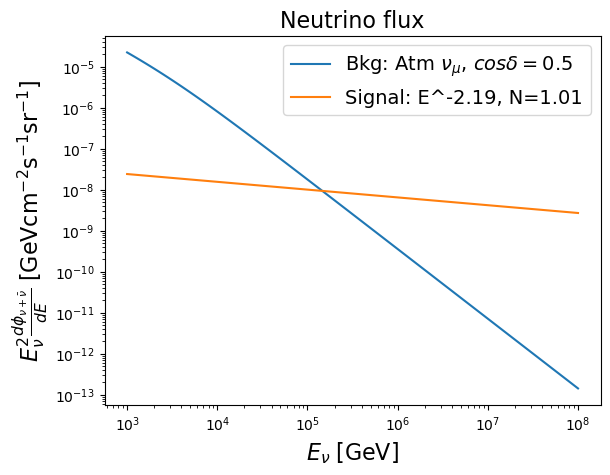

In [15]:
plt.plot(E_range, flux.getFlux(nu_type, E_range, 0.5) * E_range **  2, label=r'Bkg: Atm $\nu_\mu$, $cos\delta=0.5$')
plt.plot(E_range, d_N_astro_dE(E_range ) * E_range ** 2, label='Signal: E^-2.19, N=1.01')
# plt.plot(E_range, d_N_astro_dE(E_range * 1e-3, gamma=2.52, norm=1.80) * E_range ** 2, label='Signal: SPL Diffuse')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.show()

In [16]:
test_alert = ic_alerts.iloc[11]
test_alert

NAME                              IC111012A
RUNID                                118778
EVENTID                            61465314
START            2011-10-12 20:48:17.616683
EVENTMJD                       55846.866871
I3TYPE                           gfu-bronze
RA                                   172.13
DEC                                    44.7
RA_ERR_PLUS                             1.4
RA_ERR_MINUS                           1.39
DEC_ERR_PLUS                           0.79
DEC_ERR_MINUS                          0.45
ENERGY                                115.0
FAR                                    0.57
SIGNAL                                0.434
CASCADE_SCR                             0.0
SKIMMING_SCR                            0.0
START_SCR                               0.0
STOP_SCR                                0.0
THRGOING_SCR                            1.0
CR_VETO                               False
OTHER_I3TYPES                           NaN
Name: 11, dtype: object

In [17]:
print('IceCat-1 signalness: ', test_alert['SIGNAL'])
print('Integrated signalness: ', signalness_int(test_alert['ENERGY'] * 1e3, test_alert['DEC'], debug=True))
print('Differential signalness: ', signalness_diff(test_alert['ENERGY'] * 1e3, test_alert['DEC'], debug=True))

print('Eff area: ',  effective_area(test_alert['ENERGY'] * 1e3, test_alert['DEC']), ' cm^2') 

IceCat-1 signalness:  0.434

Itegration values
E_nu:  115000.0  GeV
dec:  44.7  deg
integration range: [ 115000.00000000003 ,  1000000000.0 ]
A_eff range: [ 0.0 ,  351477.79810603184 ] cm^2
N_s:  1.4486952315899502e-08
N_b:  5.090250345448282e-09 

Integrated signalness:  0.7399909254911986

Differential values
E_nu:  115000.0  GeV
dec:  44.7  deg
dN_s:  7.436919891480412e-19
dN_b:  7.626017660129836e-19 

Differential signalness:  0.4937230779852364
Eff area:  102101.75564606085  cm^2


I want to test how does my signalness computation change with E_max:
$$
N(E>E_\nu) = \int_{E_\nu}^{E_{max}}\frac{dN}{dE}dE
$$

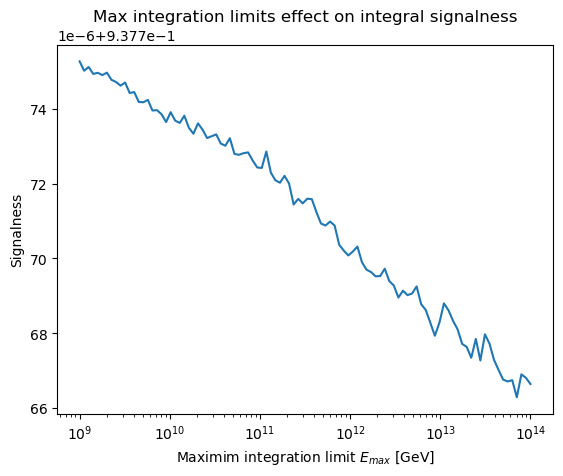

In [23]:
sig_evolution = []
E_range =  np.logspace(9, 14, 100)
for E_max in E_range:
    sig_evolution.append(signalness_int(ic_alerts.iloc[0]['ENERGY'] * 1e3, ic_alerts.iloc[0]['DEC'], E_max=E_max))
plt.plot(E_range, sig_evolution)
plt.xscale('log')
plt.xlabel(r'Maximim integration limit $E_{max}$ [GeV]')
plt.ylabel('Signalness')
plt.title('Max integration limits effect on integral signalness')
# plt.ylim(0.98, 1)
plt.show()

In [19]:
# sig_evolution

In [20]:
E_nu = 1e5
int_range = np.logspace(np.log10(E_nu), np.log10(E_max), 1000)
step = int_range[1:] - int_range[:-1]

# Thoughts
I think the effective  area needs to be in cm^2 in order to be able to multiply it correctly.Tomorrow I  can  checl with marek to see if I'm doing this  right or not.

In [22]:
#check scipy.trapezoid:
N = 100
x_log = np.logspace(1, 5, N)
x_lin = np.linspace(10, 1e5, N)
y_log = x_log ** 2
y_lin = x_lin **  2

log_int = scipy.integrate.trapezoid(y_log, x_log)
lin_int =  scipy.integrate.trapezoid(y_lin, x_lin)

anal_int = 1/3 * (1e5 ** 3 - 10 **3 )

print('analitical int: ', np.format_float_scientific(anal_int))
print('log spaced data:  ', np.format_float_scientific(log_int))
print('lin spaced data: ', np.format_float_scientific(lin_int))
print('log diff: ', np.abs(anal_int - log_int) / anal_int , '% lin diff: ', np.abs(anal_int- lin_int)/anal_int, '%  log/lin: ', log_int/lin_int) 


#Therefore, trapezoid should work fine for logspaced data for a sufficienty

analitical int:  3.33333333333e+14
log spaced data:   3.3381314368201675e+14
lin spaced data:  3.333503332995e+14
log diff:  0.0014394310470516895 % lin diff:  5.0999899500051e-05 %  log/lin:  1.0013883603413138


## Meetings:
Signalness is computedwith muon energy,  only neutrino energy is publish. Maybe if you know the spectral index you can compute this from the neutrino energy.